In [ ]:
import warnings
warnings.filterwarnings('ignore')
import os
import scanpy as sc
import pandas as pd
import squidpy as sq
import anndata as ad
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
in_dir = "../../results/04_spatial_clustering/01_run_cellcharter"
out_dir = '../../results/04_spatial_clustering/02_viz_celltype'

os.makedirs(out_dir, exist_ok=True)

In [3]:
adata = sc.read_h5ad(f"{in_dir}/adata_cellcharter_merged.h5ad")

In [4]:
df = pd.DataFrame(adata.obsm['X_cell2location'])

# split columns by _ and take last part as cell type
df.columns = df.columns.str.split('_').str[-1]
df['cluster_cellcharter'] = adata.obs['cluster_cellcharter'].values

In [5]:
# group by cluster and calculate mean cell type proportions
df = df.groupby('cluster_cellcharter').mean()

In [6]:
df.to_csv(f"{out_dir}/cellcharter_clusters_celltype_proportions.tsv", sep="\t")

In [10]:
df

,ATL,CNT,DCT,DTL,EC,FIB,IC,B,M2,MAST,...,ncMON,pDC,NEU,PC,PEC,POD,PT,PapE,TAL,P
cluster_cellcharter,,,,,,,,,,,,,,,,,,,,,
0,0.003224,0.082184,0.113965,0.005976,0.024977,0.036552,0.089293,0.003846,0.010028,0.005621,...,0.006760,0.003438,0.005341,0.056013,0.003842,0.004925,0.402407,0.002249,0.080595,0.031627
1,0.019132,0.021300,0.017553,0.021593,0.055888,0.105731,0.035494,0.012691,0.033077,0.017345,...,0.018252,0.022738,0.022211,0.037678,0.010986,0.002799,0.299228,0.015024,0.093548,0.035264
2,0.003222,0.009399,0.028799,0.005387,0.125360,0.038261,0.010826,0.007588,0.015718,0.010748,...,0.018491,0.009147,0.009044,0.003504,0.031641,0.137475,0.380490,0.002663,0.009847,0.083433
3,0.012755,0.031559,0.038403,0.016257,0.073853,0.105160,0.034415,0.021293,0.035962,0.019513,...,0.032407,0.024832,0.024366,0.019218,0.027507,0.054634,0.114836,0.011579,0.058241,0.083598
4,0.003192,0.006739,0.017542,0.024879,0.015177,0.036222,0.012442,0.003858,0.008455,0.005934,...,0.004761,0.004335,0.004586,0.079756,0.002931,0.002460,0.402746,0.001799,0.314255,0.015801
5,0.007695,0.070654,0.073744,0.008615,0.044592,0.022451,0.071986,0.010314,0.015340,0.016408,...,0.011395,0.012430,0.019451,0.028140,0.007948,0.010736,0.292990,0.008556,0.177706,0.015227
6,0.005759,0.001043,0.001411,0.054094,0.048132,0.100919,0.002185,0.007808,0.028002,0.005216,...,0.022164,0.007796,0.008069,0.024021,0.005070,0.000859,0.127385,0.003289,0.297743,0.172303
7,0.008310,0.001593,0.001541,0.081867,0.018666,0.072818,0.014721,0.004030,0.008709,0.006604,...,0.005424,0.004856,0.004700,0.155785,0.002385,0.000399,0.046919,0.002432,0.509180,0.014583
8,0.004461,0.068302,0.061637,0.009667,0.060264,0.058186,0.066691,0.009274,0.017913,0.008325,...,0.023636,0.008957,0.008424,0.034529,0.017124,0.044821,0.198113,0.006254,0.078461,0.132229


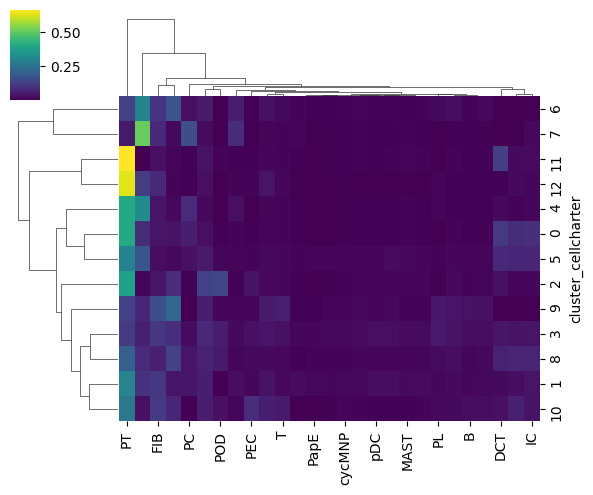

In [7]:
sns.clustermap(df, cmap='viridis', figsize=(6, 5))

In [27]:
# computer fold change for each cell type in each cluster vs all other clusters
df_fc = pd.DataFrame()
for cluster in df.index:
    cluster_mean = df.loc[cluster]
    other_mean = df.drop(cluster).mean()
    fc = (cluster_mean + 1e-9) / (other_mean + 1e-9)
    df_fc = pd.concat([df_fc, fc], axis=1)

df_fc.columns = df.index
df_fc = df_fc.T

In [28]:
df_fc

,ATL,CNT,DCT,DTL,EC,FIB,IC,B,M2,MAST,...,ncMON,pDC,NEU,PC,PEC,POD,PT,PapE,TAL,P
cluster_cellcharter,,,,,,,,,,,,,,,,,,,,,
0,0.501799,3.236269,3.428528,0.281333,0.494883,0.480591,3.415102,0.328156,0.381482,0.603141,...,0.406688,0.347520,0.498381,1.685287,0.217291,0.198691,1.358834,0.455550,0.549735,0.440719
1,3.752730,0.699094,0.425273,1.082960,1.166893,1.504178,1.158822,1.155474,1.357489,2.079052,...,1.165280,2.744362,2.385770,1.083812,0.642972,0.112124,0.981913,3.880802,0.642825,0.493489
2,0.501603,0.298776,0.713948,0.253024,2.977254,0.503998,0.331222,0.665102,0.608915,1.208610,...,1.182016,0.971253,0.869034,0.093162,2.059377,10.003348,1.276952,0.543292,0.064567,1.237065
3,2.265767,1.065714,0.971317,0.797542,1.591733,1.495036,1.120285,2.073941,1.490630,2.390650,...,2.237509,3.061653,2.668712,0.529389,1.751084,2.646156,0.358745,2.784312,0.392276,1.239770
4,0.496685,0.212711,0.424990,1.265141,0.295918,0.476074,0.382234,0.329190,0.320062,0.638534,...,0.283597,0.441542,0.425479,2.551555,0.165073,0.098410,1.360108,0.361722,2.471833,0.216211
5,1.271597,2.680799,2.015292,0.409818,0.913083,0.290703,2.609247,0.922359,0.593549,1.948418,...,0.701877,1.359266,2.038912,0.791352,0.458408,0.441715,0.959808,1.939980,1.282952,0.208227
6,0.927026,0.032441,0.033114,3.139373,0.991560,1.427573,0.065410,0.685474,1.129630,0.557691,...,1.445066,0.818029,0.769328,0.669076,0.288435,0.034173,0.399252,0.678221,2.316879,2.869875
7,1.384956,0.049603,0.036172,5.488418,0.366014,0.997036,0.454911,0.344283,0.329922,0.714881,...,0.324136,0.496791,0.436397,6.250895,0.133962,0.015855,0.144026,0.494315,4.591724,0.199265
8,0.705813,2.572455,1.639246,0.461811,1.267894,0.783618,2.379285,0.823010,0.698929,0.915406,...,1.553505,0.949444,0.805422,0.985792,1.033172,2.088173,0.632613,1.358923,0.534532,2.086360


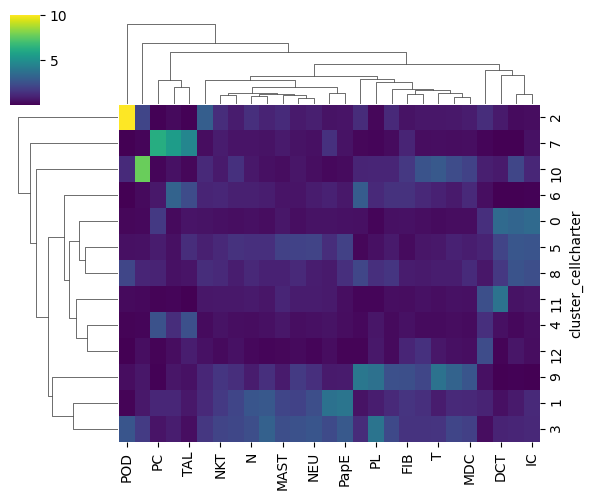

In [29]:
sns.clustermap(df_fc, cmap='viridis', figsize=(6, 5))

In [31]:
df_fc.to_csv(f"{out_dir}/cellcharter_clusters_celltype_fold_change.csv")

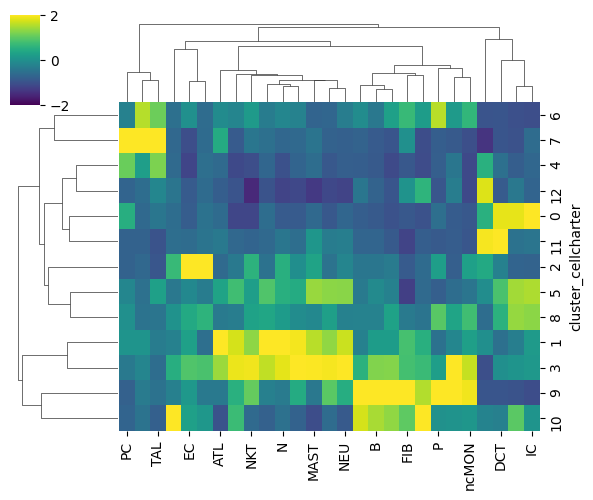

In [8]:
normalized_df = df.apply(lambda x: (x - np.mean(x)) / np.std(x), axis=0)

sns.clustermap(normalized_df, cmap='viridis', figsize=(6, 5), vmax=2, vmin=-2)

In [9]:
normalized_df.to_csv(f"{out_dir}/cluster_celltype_proportions_normalized.csv")